# Import file

In [9]:
import sys
import csv
import math
import random
import platform
import subprocess
from pathlib import Path
from contextlib import contextmanager

# 1. Tự động dò tìm thư mục gốc dự án (chứa thư mục curves/) bất kể mở notebook từ đâu
cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
SCRIPTS_DIR = ROOT_DIR / "scripts"

for path in (str(ROOT_DIR), str(SCRIPTS_DIR)):
    if path not in sys.path:
        sys.path.insert(0, path)

# 2. Import các module cốt lõi từ curves/ và scripts/
from curves.ecc import ECC, Point, FindOrder
from curves.pohlig_hellman import pohlig_hellman_ecc
from curves.bsgs import BSGS_ECC
from curves.pollard_rho import Pollard_Rho_ECC
from scripts.measure_harness import measure


# 3. Các hàm toán học & công cụ đo lường dùng chung cho toàn bộ notebook
def factorize(n: int) -> dict[int, int]:
    """Phân tích thừa số nguyên tố của bậc nhóm n để đánh giá độ trơn (B-smooth)."""
    factors = {}
    d, temp = 2, n
    while d * d <= temp:
        while temp % d == 0:
            factors[d] = factors.get(d, 0) + 1
            temp //= d
        d += 1
    if temp > 1:
        factors[temp] = factors.get(temp, 0) + 1
    return factors


def _mod_sqrt(n: int, p: int) -> int | None:
    """Tính căn bậc hai modulo p bằng Tonelli-Shanks."""
    if pow(n, (p - 1) // 2, p) != 1:
        return None
    if p % 4 == 3:
        return pow(n, (p + 1) // 4, p)
    q, s = p - 1, 0
    while q % 2 == 0:
        q //= 2
        s += 1
    z = 2
    while pow(z, (p - 1) // 2, p) != p - 1:
        z += 1
    m, c, t, r = s, pow(z, q, p), pow(n, q, p), pow(n, (q + 1) // 2, p)
    while t not in (0, 1):
        i, temp = 1, (t * t) % p
        while temp != 1:
            temp = (temp * temp) % p
            i += 1
        b = pow(c, 1 << (m - i - 1), p)
        m, c, t, r = i, (b * b) % p, (t * b * b) % p, (r * b) % p
    return r if t == 1 else None


def find_generator(curve: ECC, min_order_ratio: float = 0.25) -> Point:
    """Tìm điểm sinh G có bậc đủ lớn trên đường cong y^2 = x^3 + ax + b (mod p)."""
    p = curve.p
    for x in range(1, 1000):
        rhs = (x * x * x + curve.a * x + curve.b) % p
        y = _mod_sqrt(rhs, p)
        if y is not None and curve.is_on_curve(x, y):
            pt = Point(curve, x, y)
            if FindOrder(pt) > max(10, int(p * min_order_ratio)):
                return pt
    raise RuntimeError(f"Cannot find generator mod {p}")


class ECCOpsCounter:
    def __init__(self):
        self.add_ops = 0
        self.double_ops = 0
        self.mul_ops = 0

    @property
    def total_ops(self) -> int:
        return self.add_ops + self.double_ops + self.mul_ops


@contextmanager
def track_ecc_ops():
    """Tạm thời đếm số phép cộng điểm, nhân đôi điểm và nhân vô hướng."""
    counter = ECCOpsCounter()
    orig_add = Point.__add__
    orig_mul = Point.__mul__

    def counted_add(self, other):
        if not self.is_infinity and not other.is_infinity:
            if self == other:
                counter.double_ops += 1
            else:
                counter.add_ops += 1
        return orig_add(self, other)

    def counted_mul(self, n):
        counter.mul_ops += 1
        return orig_mul(self, n)

    Point.__add__ = counted_add
    Point.__mul__ = counted_mul
    try:
        yield counter
    finally:
        Point.__add__ = orig_add
        Point.__mul__ = orig_mul


def get_cpu_freq_ghz() -> float:
    """Lấy xung nhịp CPU (GHz) để quy đổi cpu_time_ns -> cycles nếu chưa dùng RDTSC."""
    try:
        import psutil
        freq = psutil.cpu_freq()
        if freq and freq.current > 0:
            return freq.current / 1000.0
    except ImportError:
        pass
    try:
        if platform.system() == "Linux":
            with open("/proc/cpuinfo") as f:
                for line in f:
                    if "cpu MHz" in line:
                        return float(line.split(":")[1].strip()) / 1000.0
        elif platform.system() == "Windows":
            out = subprocess.check_output(["wmic", "cpu", "get", "MaxClockSpeed"], text=True)
            mhz = [int(s) for s in out.split() if s.isdigit()]
            if mhz:
                return mhz[0] / 1000.0
    except Exception:
        pass
    return 2.5


# 4. Sanity Check trên đường cong nhỏ y^2 = x^3 + 2x + 3 (mod 97)
c_test = ECC(2, 3, 97)
G_test = Point(c_test, 3, 6)
n_test = FindOrder(G_test)
k_test = 3
A_test = k_test * G_test

assert pohlig_hellman_ecc(A_test, G_test) == k_test, "PH Sanity Check FAILED"
assert Pollard_Rho_ECC(A_test, G_test) == k_test, "Pollard Rho Sanity Check FAILED"

print("Sanity Check PASSED!")
print(f"  - Root Dir      : {ROOT_DIR}")
print(f"  - Test PH & Rho : Recovered k = {k_test} on order n = {n_test}")

Sanity Check PASSED!
  - Root Dir      : /home/han-sui/ECC-Cryptanalysis
  - Test PH & Rho : Recovered k = 3 on order n = 5


# Benchmark testing

In [10]:
# Danh sách đường cong có bậc nhóm B-smooth (dễ bị Pohlig-Hellman phá giải)
SMOOTH_CURVE_SPECS = [
    ("24-bit Smooth", 2, 3, 16777213),
    ("28-bit Smooth", 2, 3, 268435399),
    ("32-bit Smooth", 1, 5, 4294967291),
    ("40-bit Smooth", 1, 7, 1099511627689),
    ("48-bit Smooth", 2, 11, 281474976710597),
]

ph_benchmarks = []
rng = random.Random(2026)

for label, a, b, p in SMOOTH_CURVE_SPECS:
    curve = ECC(a, b, p)
    G = find_generator(curve)
    order = FindOrder(G)
    factors = factorize(order)
    largest_prime_factor = max(factors.keys())
    factor_str = " * ".join(f"{prime}^{exp}" if exp > 1 else f"{prime}" for prime, exp in sorted(factors.items()))

    k_secret = rng.randint(2, order - 1)
    A = k_secret * G

    # Chạy Pohlig-Hellman trên toàn bộ dải bit (kể cả 40-bit, 48-bit)
    # Chỉ chạy BSGS và Pollard_Rho tối đa tới 32-bit để tránh treo máy
    algos = {
        "Pohlig_Hellman": lambda: pohlig_hellman_ecc(A, G),
        "BSGS": (lambda: BSGS_ECC(A, G)) if order.bit_length() <= 32 else None,
        "Pollard_Rho": (lambda: Pollard_Rho_ECC(A, G)) if order.bit_length() <= 32 else None,
    }

    for algo_name, fn in algos.items():
        if fn is None:
            continue
        repeats = 5 if order.bit_length() <= 28 else 3
        stats = measure(fn, repeat=repeats, warmup=1, memory=True)
        assert stats["result"] == k_secret, f"Sai nghiệm tại {algo_name} ({label})"

        ph_benchmarks.append({
            "Label": label,
            "Order_Bits": order.bit_length(),
            "Order": order,
            "Max_Prime_Factor": largest_prime_factor,
            "Factorization": factor_str,
            "Algorithm": algo_name,
            "Wall_ms": stats["wall_time_ns"] / 1e6,
            "CPU_ms": stats["cpu_time_ns"] / 1e6,
            "Py_Heap_KiB": stats["memory_peak_kib"],
        })

print(f"{'Curve':<14} | {'Bits':<4} | {'Max Factor':>10} | {'Algorithm':<15} | {'Wall (ms)':>10} | {'Heap (KiB)':>10}")
print("-" * 78)
for r in ph_benchmarks:
    print(
        f"{r['Label']:<14} | {r['Order_Bits']:<4} | {r['Max_Prime_Factor']:>10,} | "
        f"{r['Algorithm']:<15} | {r['Wall_ms']:>10.3f} | {r['Py_Heap_KiB']:>10.1f}"
    )

Curve          | Bits | Max Factor | Algorithm       |  Wall (ms) | Heap (KiB)
------------------------------------------------------------------------------
24-bit Smooth  | 24   |      4,567 | Pohlig_Hellman  |      1.303 |       20.6
24-bit Smooth  | 24   |      4,567 | BSGS            |      7.199 |      741.4
24-bit Smooth  | 24   |      4,567 | Pollard_Rho     |     16.546 |       20.7
28-bit Smooth  | 28   | 16,778,771 | Pohlig_Hellman  |     11.366 |      937.6
28-bit Smooth  | 28   | 16,778,771 | BSGS            |     40.223 |     2989.2
28-bit Smooth  | 28   | 16,778,771 | Pollard_Rho     |     66.876 |       41.5
32-bit Smooth  | 31   |      1,289 | Pohlig_Hellman  |      4.233 |       85.5
32-bit Smooth  | 31   |      1,289 | BSGS            |    112.189 |     7656.7
32-bit Smooth  | 31   |      1,289 | Pollard_Rho     |    170.772 |       85.6
40-bit Smooth  | 41   | 348,057,013 | Pohlig_Hellman  |    104.682 |     4213.4
48-bit Smooth  | 48   |  4,018,099 | Pohlig_Hellman

In [11]:
print("Chi tiết phân tích thừa số và hệ số tăng tốc của Pohlig-Hellman:\n")

grouped = {}
for r in ph_benchmarks:
    grouped.setdefault(r["Label"], {})[r["Algorithm"]] = r

for label, res in grouped.items():
    ph = res["Pohlig_Hellman"]
    print(f"• {label} ({ph['Order_Bits']}-bit) | n = {ph['Order']} = {ph['Factorization']}")
    print(f"    - Pohlig-Hellman : {ph['Wall_ms']:8.3f} ms | RAM: {ph['Py_Heap_KiB']:.1f} KiB")
    if "BSGS" in res:
        speedup_bsgs = res["BSGS"]["Wall_ms"] / ph["Wall_ms"]
        print(f"    - BSGS           : {res['BSGS']['Wall_ms']:8.3f} ms | RAM: {res['BSGS']['Py_Heap_KiB']:.1f} KiB (PH nhanh hơn {speedup_bsgs:.1f}x)")
    if "Pollard_Rho" in res:
        speedup_rho = res["Pollard_Rho"]["Wall_ms"] / ph["Wall_ms"]
        print(f"    - Pollard's Rho  : {res['Pollard_Rho']['Wall_ms']:8.3f} ms | RAM: {res['Pollard_Rho']['Py_Heap_KiB']:.1f} KiB (PH nhanh hơn {speedup_rho:.1f}x)")
    if "BSGS" not in res:
        est_sqrt_ops = math.isqrt(ph["Order"])
        print(f"    - BSGS / Rho     : Không khả thi trên CPU đơn (~{est_sqrt_ops:,} phép toán nhóm)")
    print()

Chi tiết phân tích thừa số và hệ số tăng tốc của Pohlig-Hellman:

• 24-bit Smooth (24-bit) | n = 8389579 = 11 * 167 * 4567
    - Pohlig-Hellman :    1.303 ms | RAM: 20.6 KiB
    - BSGS           :    7.199 ms | RAM: 741.4 KiB (PH nhanh hơn 5.5x)
    - Pollard's Rho  :   16.546 ms | RAM: 20.7 KiB (PH nhanh hơn 12.7x)

• 28-bit Smooth (28-bit) | n = 134230168 = 2^3 * 16778771
    - Pohlig-Hellman :   11.366 ms | RAM: 937.6 KiB
    - BSGS           :   40.223 ms | RAM: 2989.2 KiB (PH nhanh hơn 3.5x)
    - Pollard's Rho  :   66.876 ms | RAM: 41.5 KiB (PH nhanh hơn 5.9x)

• 32-bit Smooth (31-bit) | n = 1073757624 = 2^3 * 3 * 61 * 569 * 1289
    - Pohlig-Hellman :    4.233 ms | RAM: 85.5 KiB
    - BSGS           :  112.189 ms | RAM: 7656.7 KiB (PH nhanh hơn 26.5x)
    - Pollard's Rho  :  170.772 ms | RAM: 85.6 KiB (PH nhanh hơn 40.3x)

• 40-bit Smooth (41-bit) | n = 1099512104067 = 3^5 * 13 * 348057013
    - Pohlig-Hellman :  104.682 ms | RAM: 4213.4 KiB
    - BSGS / Rho     : Không khả thi 

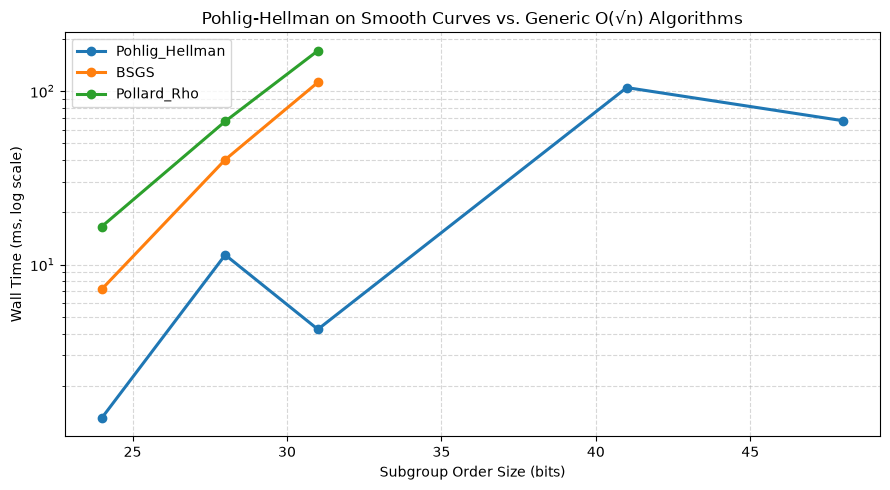

Exported PH comparison chart to: /home/han-sui/ECC-Cryptanalysis/docs/charts/pohlig_hellman_smooth.png


In [12]:
import csv
import matplotlib.pyplot as plt

CHARTS_DIR = ROOT_DIR / "docs" / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
OUT_CHART = CHARTS_DIR / "pohlig_hellman_smooth.png"

fig, ax = plt.subplots(figsize=(9, 5))

by_algo = {}
for r in ph_benchmarks:
    by_algo.setdefault(r["Algorithm"], []).append(r)

for algo, rows in by_algo.items():
    rows.sort(key=lambda x: x["Order_Bits"])
    ax.plot(
        [x["Order_Bits"] for x in rows],
        [x["Wall_ms"] for x in rows],
        marker="o",
        linewidth=2.2,
        label=algo,
    )

ax.set_yscale("log")
ax.set_title("Pohlig-Hellman on Smooth Curves vs. Generic O(√n) Algorithms")
ax.set_xlabel("Subgroup Order Size (bits)")
ax.set_ylabel("Wall Time (ms, log scale)")
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.savefig(OUT_CHART, dpi=300, bbox_inches="tight")
plt.show()
print(f"Exported PH comparison chart to: {OUT_CHART}")

# Cap nhat D2

In [13]:
import csv

CSV_PATH = ROOT_DIR / "data" / "D2_ecdlp_benchmarks.csv"
CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
CPU_GHZ = get_cpu_freq_ghz()

CSV_COLUMNS = [
    "curve_type",
    "target_bits",
    "prime_p",
    "subgroup_order",
    "order_bits",
    "algorithm",
    "secret_k",
    "wall_time_ns",
    "cpu_time_ns",
    "cpu_cycles",
    "cycles_source",
    "ec_add_ops",
    "ec_double_ops",
    "ec_mul_ops",
    "total_ec_ops",
    "memory_peak_kib",
    "rss_peak_kib",
]

# 1. Đọc toàn bộ dữ liệu baseline đã có từ run_ecdlp_baselines.ipynb
# Gán mặc định curve_type = "standard" cho các dòng cũ nếu chưa có cột này,
# và chỉ loại bỏ các dòng "smooth" cũ để tránh bị nhân đôi khi chạy lại cell này.
existing_rows = []
if CSV_PATH.exists():
    with open(CSV_PATH, mode="r", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            ctype = row.get("curve_type") or "standard"
            if ctype != "smooth":
                row["curve_type"] = ctype
                existing_rows.append(row)

# 2. Thu thập dữ liệu chi tiết (ops, cycles, memory) trên các Smooth Curves
smooth_rows = []
rng_smooth = random.Random(2026)

for label, a, b, p in SMOOTH_CURVE_SPECS:
    target_bits = int(label.split("-")[0])
    curve = ECC(a, b, p)
    G = find_generator(curve)
    order = FindOrder(G)
    k_secret = rng_smooth.randint(2, order - 1)
    A = k_secret * G

    smooth_algos = {
        "Pohlig_Hellman": lambda: pohlig_hellman_ecc(A, G),
        "BSGS": (lambda: BSGS_ECC(A, G)) if order.bit_length() <= 32 else None,
        "Pollard_Rho": (lambda: Pollard_Rho_ECC(A, G)) if order.bit_length() <= 32 else None,
    }

    for algo_name, fn in smooth_algos.items():
        if fn is None:
            continue

        repeats = 5 if order.bit_length() <= 28 else 3
        stats = measure(fn, repeat=repeats, warmup=1, memory=True)
        assert stats["result"] == k_secret, f"Sai nghiệm tại {algo_name} ({label})"

        random.seed(2026)
        with track_ecc_ops() as ops:
            fn()

        cycles = stats["cpu_cycles"] if stats.get("cpu_cycles") is not None else int(stats["cpu_time_ns"] * CPU_GHZ)
        cycles_src = "rdtsc" if stats.get("cpu_cycles") is not None else "estimated_from_cpu_ns"

        row = {
            "curve_type": "smooth",
            "target_bits": target_bits,
            "prime_p": p,
            "subgroup_order": order,
            "order_bits": order.bit_length(),
            "algorithm": algo_name,
            "secret_k": k_secret,
            "wall_time_ns": stats["wall_time_ns"],
            "cpu_time_ns": stats["cpu_time_ns"],
            "cpu_cycles": cycles,
            "cycles_source": cycles_src,
            "ec_add_ops": ops.add_ops,
            "ec_double_ops": ops.double_ops,
            "ec_mul_ops": ops.mul_ops,
            "total_ec_ops": ops.total_ops,
            "memory_peak_kib": stats["memory_peak_kib"],
            "rss_peak_kib": stats.get("rss_peak_kib"),
        }
        smooth_rows.append(row)
        print(
            f"[Smooth {target_bits:>2}-bit | {algo_name:<14}] "
            f"Wall: {row['wall_time_ns']/1e6:8.2f} ms | "
            f"Cycles: {row['cpu_cycles']:>12,} | "
            f"Ops: {row['total_ec_ops']:>8,} | "
            f"Mem: {row['memory_peak_kib']:>7.1f} KiB"
        )

# 3. Gộp dữ liệu standard + smooth và ghi ra file D2_ecdlp_benchmarks.csv
final_rows = existing_rows + smooth_rows
final_rows.sort(key=lambda r: (r["curve_type"], int(r["target_bits"]), r["algorithm"]))

with open(CSV_PATH, mode="w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS, extrasaction="ignore")
    writer.writeheader()
    writer.writerows(final_rows)

print(f"\nMerged {len(existing_rows)} standard rows + {len(smooth_rows)} smooth rows -> {CSV_PATH} (Total: {len(final_rows)} rows)")

[Smooth 24-bit | Pohlig_Hellman] Wall:     1.44 ms | Cycles:    4,554,821 | Ops:      609 | Mem:    20.6 KiB
[Smooth 24-bit | BSGS          ] Wall:     7.46 ms | Cycles:   23,883,706 | Ops:    3,900 | Mem:   741.9 KiB
[Smooth 24-bit | Pollard_Rho   ] Wall:    32.92 ms | Cycles:  105,435,904 | Ops:    1,808 | Mem:    20.7 KiB
[Smooth 28-bit | Pohlig_Hellman] Wall:    11.25 ms | Cycles:   36,057,322 | Ops:    5,339 | Mem:   938.2 KiB
[Smooth 28-bit | BSGS          ] Wall:    43.70 ms | Cycles:  139,941,433 | Ops:   19,601 | Mem:  2989.2 KiB
[Smooth 28-bit | Pollard_Rho   ] Wall:    72.52 ms | Cycles:  232,297,571 | Ops:   69,840 | Mem:    41.5 KiB
[Smooth 32-bit | Pohlig_Hellman] Wall:     4.41 ms | Cycles:   14,141,036 | Ops:    1,670 | Mem:    85.5 KiB
[Smooth 32-bit | BSGS          ] Wall:   115.97 ms | Cycles:  367,397,736 | Ops:   40,567 | Mem:  7656.7 KiB
[Smooth 32-bit | Pollard_Rho   ] Wall:   180.52 ms | Cycles:  578,229,366 | Ops:   67,266 | Mem:    85.6 KiB
[Smooth 40-bit | Po